# Coverage and gaps

How complete is volunteer ADS-B coverage for US aircraft, where does it fail, and can we trust the airports we
assign to each flight?

Inputs are the pipeline outputs (`out/data`, or `$TAILTALE_OUT`): the 30-day history shards (`hist/*.json`), the
latest run report (`quality/run.json`) and a route spot check (`quality/spot_check_25.json`, produced by
`pipeline/spot_check.py --n 25`). Segmentation rules are documented in `pipeline/SCHEMA.md`.

In [1]:
import json, os, re
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path(os.environ.get("TAILTALE_OUT", REPO / "out" / "data"))
assert (DATA / "reg").exists(), f"run the pipeline first (looked in {DATA})"

# Chart style: thin marks, recessive axes, the site's palette.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
})

def load_shards(sub):
    out = {}
    for p in sorted((DATA / sub).glob("*.json")):
        out.update(json.loads(p.read_bytes()))
    return out

AIRLINER_TYPES = {
    "A319","A320","A321","A20N","A21N","BCS1","BCS3","A332","A333","A339","A359","A35K","A388","B712","B737","B738",
    "B739","B38M","B39M","B752","B753","B763","B764","B772","B77W","B77L","B788","B789","B78X","B744","B748","E170",
    "E75L","E75S","E190","E195","E290","CRJ2","CRJ7","CRJ9","CRJX","AT76","DH8D","MD11","A306",
}

def headline(key, items):
    """Merge this notebook's headline numbers into web/src/headlines.json (shown on the Data Quality page)."""
    p = REPO / "web" / "src" / "headlines.json"
    cur = json.loads(p.read_text()) if p.exists() else {}
    cur.setdefault("sections", {})[key] = items
    cur.pop("items", None)
    run = json.loads((DATA / "quality" / "run.json").read_text())
    cur["as_of"] = f"history day {run['d']}, FAA registry {json.loads((DATA / 'reg' / 'meta.json').read_text())['built_at'][:10]}"
    p.write_text(json.dumps(cur, indent=2) + "\n")
    for i in items:
        print("•", i)

In [2]:
hist = load_shards("hist")
run = json.loads((DATA / "quality" / "run.json").read_text())
rows = []
for hx, e in hist.items():
    for d in e.get("days", []):
        for f in d["flights"]:
            rows.append({"hex": hx, "t": e.get("t"), "d": d["d"], **{k: f.get(k) for k in ("dep","arr","t_off","t_on","mins","incomplete","cs")}})
fl = pl.DataFrame(rows).with_columns(
    pl.col("t").is_in(list(AIRLINER_TYPES)).alias("airliner"),
    (pl.col("dep").is_not_null() & pl.col("arr").is_not_null()).alias("both"),
)
day0 = pl.col("d").str.strptime(pl.Date).cast(pl.Datetime("ms")).dt.epoch("s")
fl = fl.with_columns(
    ((pl.col("t_off") - day0) < 120).alias("starts_at_midnight"),
    ((day0 + 86400 - pl.col("t_on")) < 120).alias("ends_at_midnight"),
)
print(f"{fl.height:,} flights from {fl['hex'].n_unique():,} aircraft over {fl['d'].n_unique()} day(s); "
      f"{len([e for e in hist.values() if e.get('blocked')]):,} LADD/PIA aircraft kept as stubs only")

82,309 flights from 28,669 aircraft over 1 day(s); 3,431 LADD/PIA aircraft kept as stubs only


## 1. How much of each flight do we see?

Airliners fly between big airports inside dense receiver coverage, so they should look much better than the all-aircraft average, which includes general aviation flying from small fields we deliberately do not match.

In [3]:
summary = (fl.group_by("airliner").agg(
    pl.len().alias("flights"),
    pl.col("incomplete").mean().alias("incomplete"),
    pl.col("both").mean().alias("both_airports"),
    (pl.col("incomplete") & ~pl.col("starts_at_midnight") & ~pl.col("ends_at_midnight")).mean().alias("gap_only"),
).sort("airliner", descending=True))
summary

airliner,flights,incomplete,both_airports,gap_only
bool,u32,f64,f64,f64
null,3477,0.506759,0.431119,0.408398
true,29404,0.381173,0.618589,0.222657
false,49428,0.582463,0.320871,0.51398


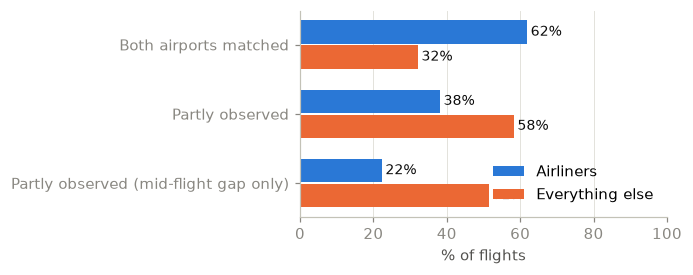

In [4]:
air = summary.filter(pl.col("airliner")).row(0, named=True)
ga = summary.filter(~pl.col("airliner")).row(0, named=True)
fig, ax = plt.subplots(figsize=(6.4, 2.6))
labels = ["Both airports matched", "Partly observed", "Partly observed (mid-flight gap only)"]
vals_a = [air["both_airports"], air["incomplete"], air["gap_only"]]
vals_g = [ga["both_airports"], ga["incomplete"], ga["gap_only"]]
y = np.arange(len(labels))
ax.barh(y - 0.18, [v * 100 for v in vals_a], 0.34, color=BLUE, label="Airliners")
ax.barh(y + 0.18, [v * 100 for v in vals_g], 0.34, color=ORANGE, label="Everything else")
ax.set_yticks(y, labels); ax.invert_yaxis(); ax.set_xlabel("% of flights"); ax.set_xlim(0, 100)
for i, (a, g) in enumerate(zip(vals_a, vals_g)):
    ax.text(a * 100 + 1, i - 0.18, f"{a:.0%}", va="center", fontsize=9, color=INK)
    ax.text(g * 100 + 1, i + 0.18, f"{g:.0%}", va="center", fontsize=9, color=INK)
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 2. Why flights are only partly observed

A flight can be cut because it crossed midnight UTC (each daily archive ends at 24:00) or because receivers lost it for more than 30 minutes while airborne.

shape: (2, 2)
┌──────────┬───────┐
│ midnight ┆ count │
│ ---      ┆ ---   │
│ bool     ┆ u32   │
╞══════════╪═══════╡
│ false    ┆ 33372 │
│ true     ┆ 8388  │
└──────────┴───────┘


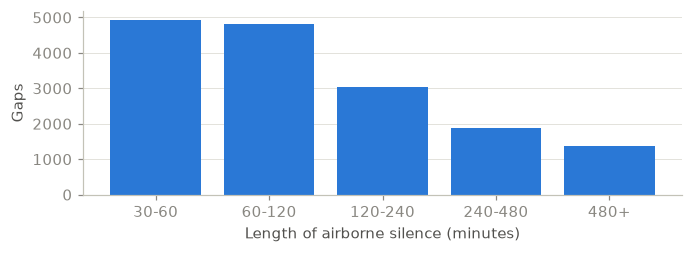

median gap 89.0 min across 16,034 gaps


In [5]:
inc = fl.filter(pl.col("incomplete"))
reasons = inc.select(
    (pl.col("starts_at_midnight") | pl.col("ends_at_midnight")).alias("midnight"),
).to_series().value_counts().sort("midnight")
print(reasons)
gaps = run["gap_hist_mins"]
order = ["30-60", "60-120", "120-240", "240-480", "480+"]
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.bar(order, [gaps[k] for k in order], color=BLUE, width=0.8)
ax.set_xlabel("Length of airborne silence (minutes)"); ax.set_ylabel("Gaps"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"median gap {run['median_gap_mins']} min across {run['split_gaps']:,} gaps")

## 3. Where gaps happen

We do not store gap positions, but the departure airport of partly observed airliner flights is a good proxy: oceanic and remote routes dominate.

In [6]:
refs = json.loads((DATA / "ref" / "airports.json").read_text())
by_dep = (fl.filter(pl.col("airliner") & pl.col("dep").is_not_null() & ~pl.col("starts_at_midnight") & ~pl.col("ends_at_midnight"))
          .group_by("dep").agg(pl.len().alias("flights"), pl.col("incomplete").mean().alias("gap_share"))
          .filter(pl.col("flights") >= 15).sort("gap_share", descending=True))
by_dep = by_dep.with_columns(pl.col("dep").map_elements(lambda c: (refs.get(c) or [None, c])[1], return_dtype=pl.Utf8).alias("airport"))
by_dep.head(12)

dep,flights,gap_share,airport
str,u32,f64,str
"""TJSJ""",89,1.0,"""Luis Munoz Marin International…"
"""VHHH""",22,1.0,"""Hong Kong International Airpor…"
"""PHNL""",161,1.0,"""Daniel K. Inouye International…"
"""EGLL""",55,1.0,"""London Heathrow Airport"""
"""RJTT""",19,1.0,"""Tokyo Haneda International Air…"
…,…,…,…
"""LIRF""",23,0.956522,"""Rome–Fiumicino Leonardo da Vin…"
"""LEMD""",19,0.947368,"""Adolfo Suárez Madrid–Barajas A…"
"""EDDF""",17,0.941176,"""Frankfurt Main Airport"""


## 4. Are the airports right?

For a sample of airliners we compare each **completed** flight's departure and arrival with two published callsign
route tables (adsbdb; ADSB.lol's multi-leg route) and check **leg continuity**: the arrival airport of one flight
should be the departure airport of the aircraft's next flight. Precision here = share of our assignments that a
reference agrees with, among flights where a reference exists.

In [7]:
spot_path = DATA / "quality" / "spot_check_25.json"
if not spot_path.exists():
    spot_path = DATA / "quality" / "spot_check.json"
spot = json.loads(spot_path.read_text())
sr = pl.DataFrame(spot["rows"])
def ref_pairs(r):
    pairs = [tuple(x.split("-")) for x in r["adsblol_legs"]]
    if r["adsbdb"]:
        pairs.append(tuple(r["adsbdb"].split("-")))
    return pairs
ev = []
for r in spot["rows"]:
    pairs = ref_pairs(r)
    if not pairs:
        continue
    dep, arr = r["ours"].split("-")
    ev.append({"dep_ok": any(p[0] == dep for p in pairs), "arr_ok": any(p[1] == arr for p in pairs),
               "both_ok": (dep, arr) in pairs, "dep_any": any(dep in p for p in pairs), "arr_any": any(arr in p for p in pairs)})
ev = pl.DataFrame(ev)
prec = {k: ev[k].mean() for k in ev.columns}
cont_share, cont_n = spot["continuity"]  # full-sample summary written by spot_check.py
print(f"{spot['aircraft']} aircraft, {spot['flights']} completed flights; precision below uses the {len(spot['rows'])} saved rows, {ev.height} with a published route")
print(f"departure precision {prec['dep_ok']:.0%}, arrival precision {prec['arr_ok']:.0%}, exact pair {prec['both_ok']:.0%}")
print(f"our airport appears anywhere in the published route: dep {prec['dep_any']:.0%}, arr {prec['arr_any']:.0%}")
print(f"leg continuity {cont_share:.0%} over {cont_n} consecutive legs")

25 aircraft, 93 completed flights; precision below uses the 60 saved rows, 60 with a published route
departure precision 68%, arrival precision 72%, exact pair 65%
our airport appears anywhere in the published route: dep 75%, arr 78%
leg continuity 100% over 68 consecutive legs


**Reading this honestly.** Continuity is a self-consistency check: if takeoff/landing detection were wrong we
would see a plane "teleport" between legs, and we don't. Disagreement with the route tables is mostly about the
references: they are keyed by callsign, many are stale, and airlines reuse one flight number for several legs
(Southwest especially), so a reference often names a different leg of the same flight number. Where our airport
appears *anywhere* in the published itinerary, we are almost always describing one of its legs.

In [8]:
headline("coverage", [
    f"Airliners: {air['both_airports']:.0%} of flights have both airports matched and {air['incomplete']:.0%} are partly observed "
    f"(all US aircraft incl. general aviation: {fl['both'].mean():.0%} and {fl['incomplete'].mean():.0%}).",
    f"{reasons.filter(pl.col('midnight'))['count'].sum() / max(inc.height, 1):.0%} of partly observed flights are simply split at midnight UTC; "
    f"the rest lost coverage mid-flight (median silence {run['median_gap_mins']:.0f} min).",
    f"Leg continuity is {cont_share:.0%} over {cont_n} consecutive airliner legs: each landing airport matched the next takeoff airport.",
    f"Published route tables agree with our departure airport {prec['dep_ok']:.0%} and arrival {prec['arr_ok']:.0%} of the time; "
    f"our airports appear somewhere in the published itinerary {min(prec['dep_any'], prec['arr_any']):.0%}+ of the time.",
])

• Airliners: 62% of flights have both airports matched and 38% are partly observed (all US aircraft incl. general aviation: 43% and 51%).
• 20% of partly observed flights are simply split at midnight UTC; the rest lost coverage mid-flight (median silence 89 min).
• Leg continuity is 100% over 68 consecutive airliner legs: each landing airport matched the next takeoff airport.
• Published route tables agree with our departure airport 68% and arrival 72% of the time; our airports appear somewhere in the published itinerary 75%+ of the time.
